# R² and Adjusted R²

## Learning Objectives
- Understand residual variation and total variation.
- Calculate R² and adjusted R².
- Compare regression models with different numbers of features.
- Understand why training R² alone is not enough.

We will use a small synthetic house-price dataset for demonstration.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.DataFrame({
    "size": [800, 1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000],
    "bedrooms": [2, 2, 3, 3, 3, 4, 4, 4, 5, 5],
    "location_score": [1, 2, 1, 2, 3, 2, 3, 3, 4, 4],
    "irrelevant_feature": [7, 2, 9, 1, 6, 3, 8, 4, 10, 5],
    "price": [150, 180, 210, 250, 290, 310, 350, 370, 420, 450]
})

data

,size,bedrooms,location_score,irrelevant_feature,price
0,800,2,1,7,150
1,1000,2,2,2,180
2,1200,3,1,9,210
3,1500,3,2,1,250
4,1800,3,3,6,290
5,2000,4,2,3,310
6,2200,4,3,8,350
7,2500,4,3,4,370
8,2800,5,4,10,420
9,3000,5,4,5,450


## 1. Residuals

A residual is the difference between an observed target and its prediction.

$$
e_i = y_i - \hat{y}_i
$$

- Positive residual: the model predicted below the observed value.
- Negative residual: the model predicted above the observed value.

The sum of squared residuals is:

$$
SS_{res} = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

In [3]:
X = data[["size"]].to_numpy(dtype=float)
y = data["price"].to_numpy(dtype=float)

# Add the intercept column.
X_design = np.column_stack([np.ones(len(X)), X])

# Estimate coefficients using least squares.
theta = np.linalg.lstsq(X_design, y, rcond=None)[0]

y_pred = X_design @ theta
residuals = y - y_pred

results = pd.DataFrame({
    "Actual Price": y,
    "Predicted Price": y_pred,
    "Residual": residuals
})

results.round(2)

,Actual Price,Predicted Price,Residual
0,150.0,153.97,-3.97
1,180.0,180.64,-0.64
2,210.0,207.32,2.68
3,250.0,247.32,2.68
4,290.0,287.33,2.67
5,310.0,314.00,-4.00
6,350.0,340.67,9.33
7,370.0,380.68,-10.68
8,420.0,420.69,-0.69
9,450.0,447.36,2.64


## 2. Total Sum of Squares

The total sum of squares measures variation around the observed target mean.

$$
SS_{tot} = \sum_{i=1}^{n}(y_i-\bar{y})^2
$$

The mean-prediction baseline predicts the same mean value for every observation.

In [4]:
y_mean = np.mean(y)

ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - y_mean) ** 2)

print(f"Target mean: {y_mean:.2f}")
print(f"Residual sum of squares (SSres): {ss_res:.2f}")
print(f"Total sum of squares (SStot): {ss_tot:.2f}")

Target mean: 298.00
Residual sum of squares (SSres): 262.22
Total sum of squares (SStot): 91960.00


## 3. R²: Coefficient of Determination

$$
R^2 = 1 - \frac{SS_{res}}{SS_{tot}}
$$

R² compares the model's squared-error performance against the mean-prediction baseline.

In [5]:
def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    if np.isclose(ss_tot, 0):
        raise ValueError("R² is undefined when the observed target has zero variation.")

    return 1 - (ss_res / ss_tot)


r2 = calculate_r2(y, y_pred)

print(f"R²: {r2:.4f}")
print(f"Explained variation relative to the mean baseline: {r2 * 100:.2f}%")

R²: 0.9971
Explained variation relative to the mean baseline: 99.71%


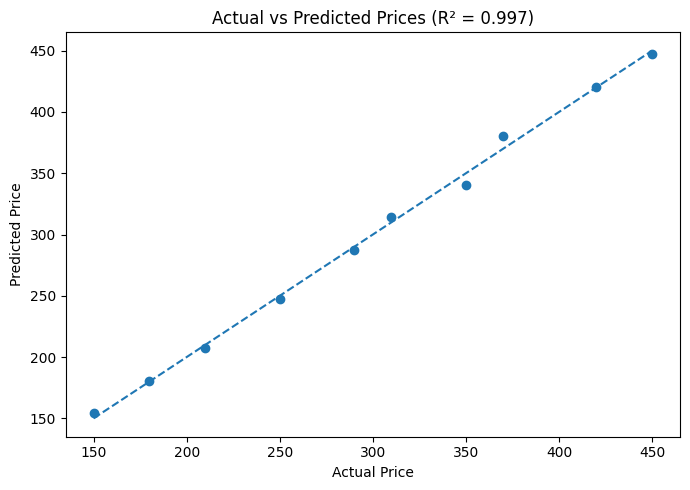

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(y, y_pred)

lower = min(y.min(), y_pred.min())
upper = max(y.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted Prices (R² = {r2:.3f})")
plt.tight_layout()
plt.show()

## 4. Adjusted R²

Adjusted R² accounts for the number of predictors and observations.

$$
R^2_{adj}
=
1-(1-R^2)\frac{n-1}{n-p-1}
$$

Where:
- $n$ = number of observations.
- $p$ = number of independent features, excluding the intercept.
- $n-p-1$ = residual degrees of freedom.

The number of predictors must be small enough that the residual degrees of freedom remain positive.

In [7]:
def calculate_adjusted_r2(r2, n, p):
    if n - p - 1 <= 0:
        raise ValueError(
            "Adjusted R² requires n - p - 1 > 0."
        )

    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


n = len(y)
p = X.shape[1]

adjusted_r2 = calculate_adjusted_r2(r2, n, p)

print(f"Observations (n): {n}")
print(f"Predictors (p): {p}")
print(f"R²: {r2:.4f}")
print(f"Adjusted R²: {adjusted_r2:.4f}")

Observations (n): 10
Predictors (p): 1
R²: 0.9971
Adjusted R²: 0.9968


## 5. Comparing Models with Different Feature Counts

We will compare models using:
1. House size.
2. House size and bedrooms.
3. House size, bedrooms, and location.
4. The previous features plus an illustrative irrelevant feature.

The dataset is synthetic. The irrelevant feature is included to demonstrate that a higher training R² does not automatically mean a predictor is useful.

We use ordinary least squares with an intercept for each model.

In [8]:
feature_sets = {
    "Size": ["size"],
    "Size + Bedrooms": ["size", "bedrooms"],
    "Size + Bedrooms + Location": [
        "size", "bedrooms", "location_score"
    ],
    "All Features": [
        "size", "bedrooms", "location_score", "irrelevant_feature"
    ]
}

comparison = []

for model_name, features in feature_sets.items():
    X_model = data[features].to_numpy(dtype=float)
    X_model_design = np.column_stack([
        np.ones(len(X_model)),
        X_model
    ])

    coefficients = np.linalg.lstsq(
        X_model_design, y, rcond=None
    )[0]

    predictions = X_model_design @ coefficients

    model_r2 = calculate_r2(y, predictions)
    model_adjusted_r2 = calculate_adjusted_r2(
        model_r2,
        n=len(y),
        p=len(features)
    )

    comparison.append({
        "Model": model_name,
        "Predictor Count": len(features),
        "R²": model_r2,
        "Adjusted R²": model_adjusted_r2
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.round(4)

,Model,Predictor Count,R²,Adjusted R²
0,Size,1,0.9971,0.9968
1,Size + Bedrooms,2,0.9973,0.9965
2,Size + Bedrooms + Location,3,0.9983,0.9974
3,All Features,4,0.9983,0.9969


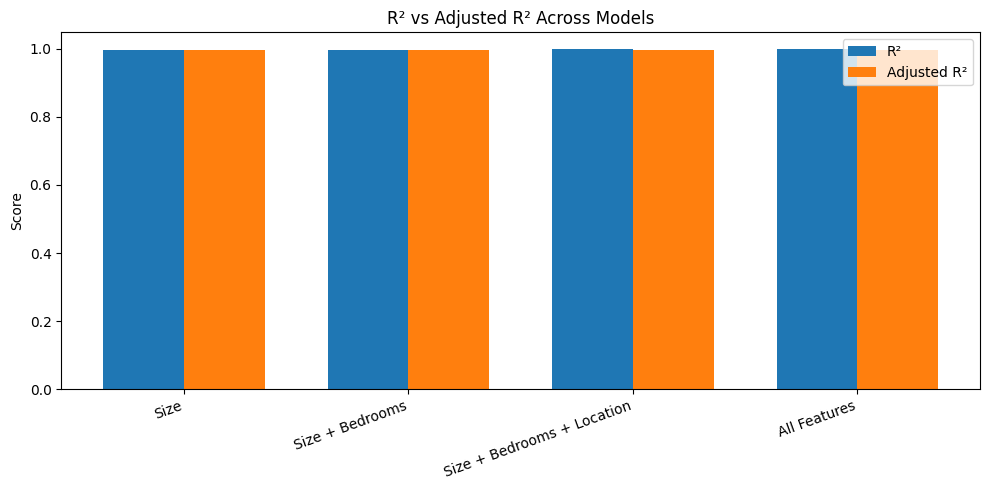

In [9]:
x = np.arange(len(comparison_df))
width = 0.36

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    comparison_df["R²"],
    width,
    label="R²"
)

plt.bar(
    x + width / 2,
    comparison_df["Adjusted R²"],
    width,
    label="Adjusted R²"
)

plt.xticks(x, comparison_df["Model"], rotation=20, ha="right")
plt.ylabel("Score")
plt.title("R² vs Adjusted R² Across Models")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Interpretation

When comparing the results, remember:

- Training R² cannot decrease when predictors are added to ordinary least squares with an intercept.
- Adjusted R² can increase or decrease.
- A predictor that raises R² may not provide enough improvement to raise adjusted R².
- Adjusted R² is a comparison metric, not proof that a predictor is statistically significant or causally useful.
- Neither metric guarantees performance on unseen data.

The results depend on this synthetic dataset; they are not universal values.

## 7. Self-Check

Try answering these before revealing the answers.

1. What is a residual?
2. What do SSres and SStot measure?
3. What does an R² of 0.70 mean?
4. Can R² be negative?
5. Why can training R² increase after adding a useless feature?
6. What do n and p represent in adjusted R²?
7. Can adjusted R² decrease when a feature is added?
8. Why should models also be evaluated on held-out data?

### Answers

1. Observed target minus predicted target.
2. SSres measures squared prediction errors; SStot measures squared deviations from the observed mean.
3. The model explains 70% of target variation relative to the mean-prediction baseline on the evaluated data.
4. Yes. The model can perform worse than predicting the observed mean.
5. Ordinary least squares can assign the new feature a zero coefficient, so training R² cannot decrease.
6. n is the number of observations; p is the number of independent predictors, excluding the intercept.
7. Yes. The fit improvement may not offset the feature-count penalty.
8. Training scores alone do not establish how well a model generalizes to unseen observations.